In [24]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statistics


# Define folder path and experimental file name
Folder_path = "/Users/mariaclaudia/Documents/Lab/Experiments/Calcium/Fura 2/250521 SHSY5Y CDN and FASN drugs"
exp_name = "SHSY5Y_CDN_250521"
exp_file_name = "Data 05-22-25-153906 CDN plate.txt"  # Replace with the actual file name
plate_plan_name = "Data 05-22-25-153906 CDN plate plan.csv"  # Replace with the actual plate plan name

# Read plate plan and create a dictionary to store positions for each unique sample
plate_plan = pd.read_csv(os.path.join(Folder_path, plate_plan_name), header=None).values
print("Plate plan shape:", plate_plan.shape)
print(plate_plan)

Plate plan shape: (8, 8)
[['_' '_' '_' '_' '_' '_' '_' '_']
 ['_' '_' '_' '_' 'UT' 'UT' 'UT' 'UT']
 ['_' '_' '_' '_' 'DMSO' 'DMSO' 'DMSO' 'DMSO']
 ['_' '_' '_' '_' 'CDN' 'CDN' 'CDN' 'CDN']
 ['_' '_' '_' '_' 'UT' 'UT' 'UT' 'UT']
 ['_' '_' '_' '_' 'DMSO' 'DMSO' 'DMSO' 'DMSO']
 ['_' '_' '_' '_' 'CDN' 'CDN' 'CDN' 'CDN']
 ['_' '_' '_' '_' '_' '_' '_' '_']]


In [25]:
from plate_coordinates import extract_plate_coordinates

coordinates_dict, non_empty_coordinates = extract_plate_coordinates(plate_plan)

print("Coordinates Dictionary:")
print(coordinates_dict)

print("\nNon-Empty Coordinates:")
print(non_empty_coordinates)


Coordinates Dictionary:
{'UT': ['B5', 'B6', 'B7', 'B8', 'E5', 'E6', 'E7', 'E8'], 'DMSO': ['C5', 'C6', 'C7', 'C8', 'F5', 'F6', 'F7', 'F8'], 'CDN': ['D5', 'D6', 'D7', 'D8', 'G5', 'G6', 'G7', 'G8']}

Non-Empty Coordinates:
['B5', 'B6', 'B7', 'B8', 'C5', 'C6', 'C7', 'C8', 'D5', 'D6', 'D7', 'D8', 'E5', 'E6', 'E7', 'E8', 'F5', 'F6', 'F7', 'F8', 'G5', 'G6', 'G7', 'G8']


In [26]:
# Import the TXT file into a DataFrame and keep rows from row 4 (header) onwards
# Some files may not be UTF-8 encoded; try default first and fall back to latin-1 to avoid UnicodeDecodeError.
read_kwargs = dict(
    filepath_or_buffer=os.path.join(Folder_path, exp_file_name),
    sep=None,
    skiprows=4,  # change depending on output file, more recent ones seem to have 4 rows of head
    engine="python",
    usecols=non_empty_coordinates
)

try:
    fs_data = pd.read_csv(**read_kwargs)
except UnicodeDecodeError:
    # Fallback encoding that can decode any byte sequence without raising
    read_kwargs['encoding'] = 'latin-1'
    fs_data = pd.read_csv(**read_kwargs)

print(fs_data.columns.tolist())

['B5', 'B6', 'B7', 'B8', 'C5', 'C6', 'C7', 'C8', 'D5', 'D6', 'D7', 'D8', 'E5', 'E6', 'E7', 'E8', 'F5', 'F6', 'F7', 'F8', 'G5', 'G6', 'G7', 'G8']


In [27]:
# Exclude any row after the 26th (up to 100 s), different for SOCE
raw_data_trimmed = fs_data.iloc[:26].copy()  # Ensure this is a copy
#raw_data_trimmed = fs_data.iloc[:120].copy() #for SOCE

# Transform specified columns into floats
float_raw_data_trimmed = raw_data_trimmed.copy()

for col in non_empty_coordinates:
    float_raw_data_trimmed[col] = pd.to_numeric(raw_data_trimmed[col], errors='coerce')

# Print the resulting DataFrame
print(float_raw_data_trimmed.head(45))

          B5        B6        B7        B8        C5        C6        C7  \
0   1.327682  1.401389  1.414072  1.425185  1.393120  1.296675  1.308636   
1   1.374161  1.420888  1.356516  1.405832  1.376142  1.403340  1.377653   
2   1.363978  1.414499  1.341701  1.378810  1.351028  1.418579  1.373433   
3   1.362864  1.345117  1.355936  1.421087  1.381564  1.373746  1.374262   
4   1.380641  1.352769  1.272175  1.386701  1.361161  1.368682  1.311955   
5   1.392537  1.391406  1.414133  1.403228  1.378951  1.367048  1.351201   
6   1.387876  1.407541  1.330438  1.403578  1.502500  1.440551  1.394696   
7   1.389506  1.359926  1.257249  1.398944  1.272317  1.486229  1.402246   
8   0.719221  0.689718  0.744538  0.741676  0.712622  0.758929  0.756892   
9   1.078506  1.082177  1.037686  1.086445  1.135055  1.169449  1.294601   
10  1.106531  1.065300  1.115319  1.040364  1.167027  1.206339  1.273389   
11  1.096551  1.034618  1.080290  1.060695  1.181153  1.242856  1.308816   
12  1.127684

In [28]:
# Compute the baseline (average of rows 1-8) and the peak (max of rows 9-16); SOCE is different
baseline = float_raw_data_trimmed.iloc[:8].mean()
peak = float_raw_data_trimmed.iloc[8:16].max()
#peak = float_raw_data_trimmed.iloc[56:66].max() #for SOCE

# Calculate peak amplitude (peak - baseline)
peak_ampli = peak - baseline
print(peak_ampli)

B5   -0.244722
B6   -0.304515
B7   -0.227459
B8   -0.280697
C5   -0.123514
C6   -0.070769
C7   -0.037601
C8   -0.022950
D5    0.357591
D6    0.234601
D7    0.223741
D8    0.336177
E5   -0.079904
E6   -0.115462
E7   -0.080709
E8   -0.148370
F5    0.069665
F6    0.020158
F7    0.279715
F8    0.101592
G5    0.410505
G6    0.214891
G7    0.376643
G8    0.246050
dtype: float64


In [29]:
median_value = peak_ampli.median()
print("Median:", median_value)

# Compute threshold
threshold = median_value / 2
print("Threshold:", threshold)


Median: -0.001396062500000017
Threshold: -0.0006980312500000085


In [30]:
# Exclude columns where peak_ampli < threshold
filtered_columns = peak_ampli[peak_ampli >= threshold].index
excluded_columns = peak_ampli.index.difference(filtered_columns)
print(f"The following wells did not respond and were excluded: {list(excluded_columns)}")

data_filtered = float_raw_data_trimmed[filtered_columns]

filtered_ampli = peak_ampli[filtered_columns]
print(filtered_ampli)

The following wells did not respond and were excluded: ['B5', 'B6', 'B7', 'B8', 'C5', 'C6', 'C7', 'C8', 'E5', 'E6', 'E7', 'E8']
D5    0.357591
D6    0.234601
D7    0.223741
D8    0.336177
F5    0.069665
F6    0.020158
F7    0.279715
F8    0.101592
G5    0.410505
G6    0.214891
G7    0.376643
G8    0.246050
dtype: float64


In [31]:
# Map column names in data_filtered to their corresponding samples based on the plate dictionary
traces_by_sample = []
plate_dict = {v: k for k, vals in coordinates_dict.items() for v in vals}  # Flatten the dictionary
for col in data_filtered.columns:
    traces_by_sample.append(plate_dict.get(col, col))  # Map to sample names or keep original if not found
    

# Create the new DataFrame with sample names as headers and averaged columns for each sample
final_traces = data_filtered.groupby(traces_by_sample, axis=1).mean()

/var/folders/yl/tcyvp31n0fzgz34yswf1l9g40000gn/T/ipykernel_37362/72967402.py:9: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  final_traces = data_filtered.groupby(traces_by_sample, axis=1).mean()


In [32]:
# Map indices to sample names
grouped_indices = [plate_dict.get(idx, idx) for idx in filtered_ampli.index]

# Group by sample names and compute the mean
grouped_ampli = filtered_ampli.groupby(grouped_indices).mean()
grouped_ampli_SEM = filtered_ampli.groupby(grouped_indices).sem()

In [33]:
# Save traces and amplis by sample
output_traces = os.path.join(Folder_path, f"{exp_name}_final_traces.csv")
final_traces.to_csv(output_traces)

output_amplis = os.path.join(Folder_path, f"{exp_name}_final_amplis.csv")
grouped_ampli.to_csv(output_amplis)

output_amplis_SEM = os.path.join(Folder_path, f"{exp_name}_final_amplis_SEM.csv")
grouped_ampli_SEM.to_csv(output_amplis_SEM)

print(f"Final data saved in: {Folder_path}")

Final data saved in: /Users/mariaclaudia/Documents/Lab/Experiments/Calcium/Fura 2/250521 SHSY5Y CDN and FASN drugs


Line plot saved to: /Users/mariaclaudia/Documents/Lab/Experiments/Calcium/Fura 2/250521 SHSY5Y CDN and FASN drugs/SHSY5Y_CDN_250521_traces_plot.png


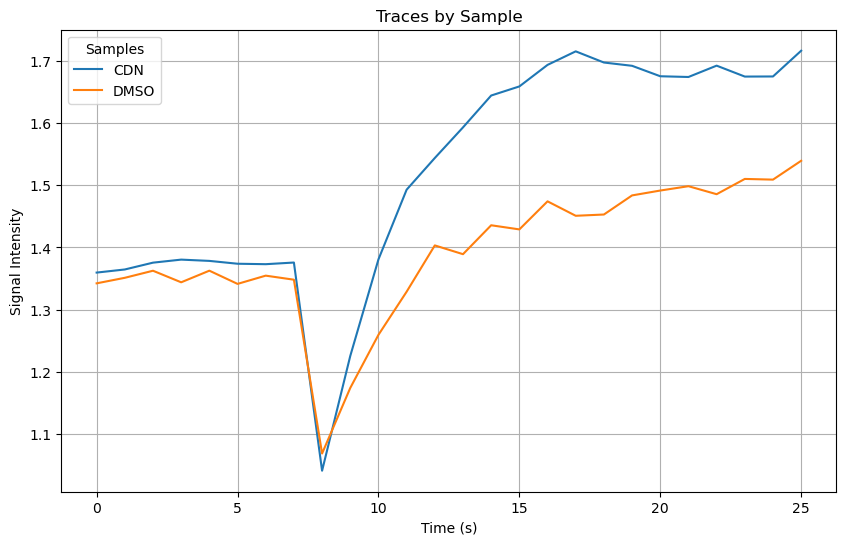

Bar graph saved to: /Users/mariaclaudia/Documents/Lab/Experiments/Calcium/Fura 2/250521 SHSY5Y CDN and FASN drugs/SHSY5Y_CDN_250521_amplitudes_plot.png


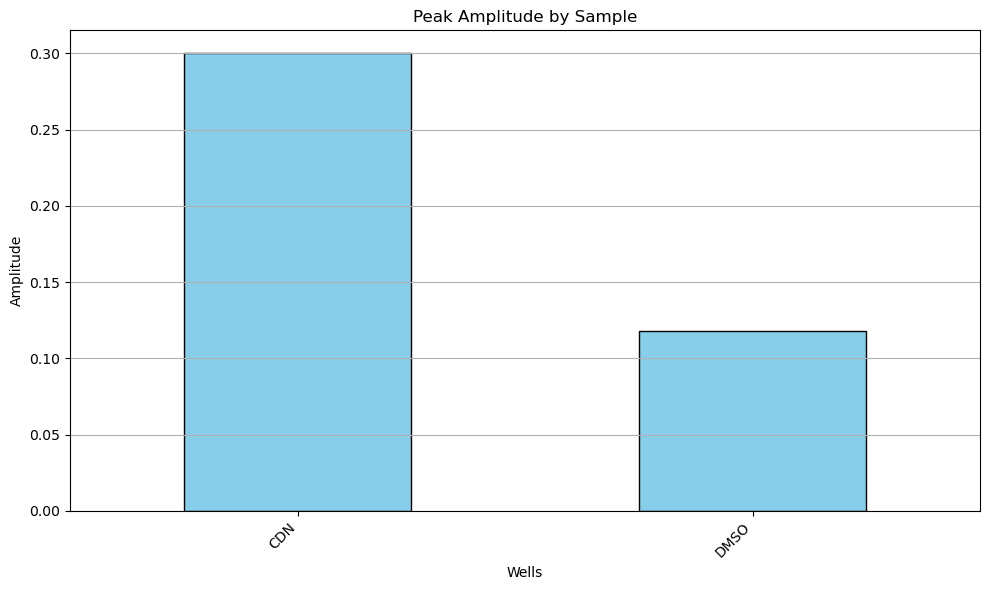

In [34]:
# Line plot for output_traces
def plot_traces(final_traces, folder_path, exp_name):
    save_path = os.path.join(folder_path, f"{exp_name}_traces_plot.png")
    
    plt.figure(figsize=(10, 6))
    for col in final_traces.columns:
        plt.plot(final_traces.index, final_traces[col], label=col)
    plt.xlabel("Time (s)")  # Customize based on your x-axis (e.g., time points)
    plt.ylabel("Signal Intensity")  # Customize based on your data
    plt.title("Traces by Sample")
    plt.legend(title="Samples")
    plt.grid(True)
    
    # Save the plot
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    print(f"Line plot saved to: {save_path}")
    plt.show()

# Bar graph for output_ampli
def plot_amplitudes(grouped_ampli, folder_path, exp_name):
    save_path = os.path.join(folder_path, f"{exp_name}_amplitudes_plot.png")
    
    plt.figure(figsize=(10, 6))
    grouped_ampli.plot(kind='bar', color='skyblue', edgecolor='black')
    plt.xlabel("Wells")
    plt.ylabel("Amplitude")
    plt.title("Peak Amplitude by Sample")
    plt.xticks(rotation=45, ha='right')  # Rotate labels for readability
    plt.grid(axis='y')
    plt.tight_layout()
    
    # Save the plot
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    print(f"Bar graph saved to: {save_path}")
    plt.show()

# Ensure the folder exists
os.makedirs(Folder_path, exist_ok=True)

# Call the plotting functions
plot_traces(final_traces, Folder_path, exp_name)
plot_amplitudes(grouped_ampli, Folder_path, exp_name)
